In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
# 타이타닉 데이터 불러오기
titanic = sns.load_dataset('titanic')

In [26]:
titanic = titanic.dropna(subset=['age', 'embarked', 'fare'])
titanic['has_family'] = ((titanic['sibsp'] + titanic['parch']) > 0).astype(int)
titanic['has_family'] = titanic['has_family'].map({0: 'Alone', 1: 'With Family'})
titanic['survived'] = titanic['survived'].map({0: 'Died', 1: 'Survived'})
print(titanic.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0      Died       3    male  22.0      1      0   7.2500        S  Third   
1  Survived       1  female  38.0      1      0  71.2833        C  First   
2  Survived       3  female  26.0      0      0   7.9250        S  Third   
3  Survived       1  female  35.0      1      0  53.1000        S  First   
4      Died       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone   has_family    age_group  
0    man        True  NaN  Southampton    no  False  With Family  Young Adult  
1  woman       False    C    Cherbourg   yes  False  With Family        Adult  
2  woman       False  NaN  Southampton   yes   True        Alone  Young Adult  
3  woman       False    C  Southampton   yes  False  With Family        Adult  
4    man        True  NaN  Southampton    no   True        Alone        Adult  


In [27]:
# 나이(age)를 범주화(구간화) 하기

titanic['age_group'] = pd.cut(
    titanic['age'],
    bins=[0, 12, 19, 30, 50, 80],
    labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']
)


C:\Users\user\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
C:\Users\user\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
C:\Users\user\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gr

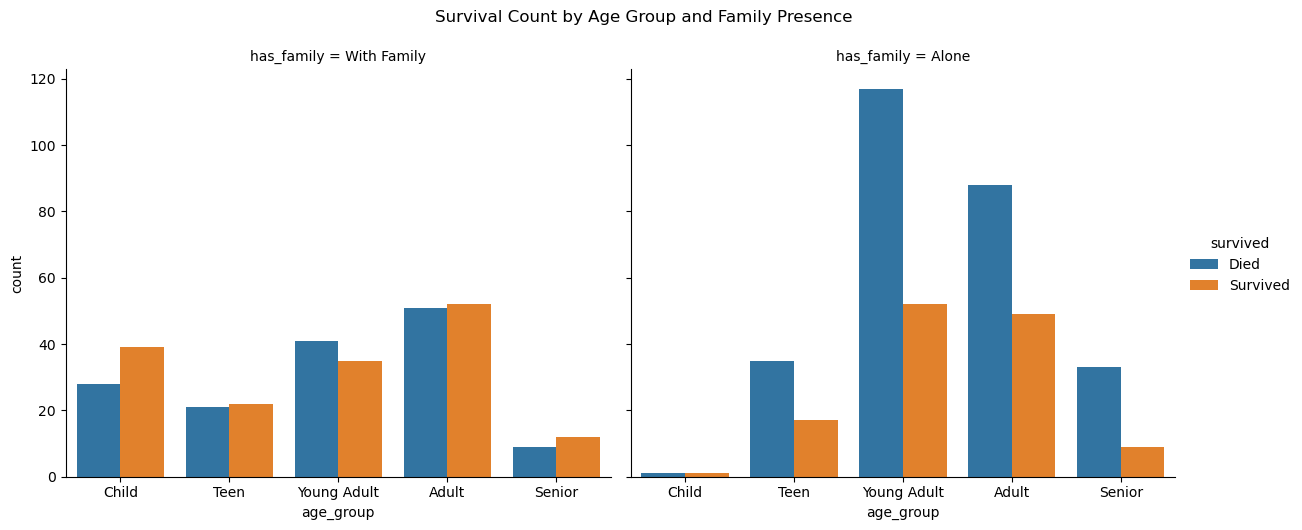

In [28]:
# 시각화1. 나이 그룹 + 가족 유무에 따른 생존자 수 시각화
sns.catplot(
    data=titanic,
    x='age_group',
    hue='survived',
    col='has_family',
    kind='count',
    height=5,
    aspect=1.2
)
plt.suptitle('Survival Count by Age Group and Family Presence', y=1.05)
plt.show()

In [38]:
# 분석: 어린이 그룹과 가족과 함께 탑승한 승객이 상대적으로 높은 생존률을 보임.
# 가족과 함께한 승객이 혼자인 승객보다 생존 확률이 높음을 알 수 있음.

분석: 어린이 그룹과 가족과 함께 탑승한 승객이 상대적으로 높은 생존률을 보입니다.
가족과 함께한 승객이 혼자인 승객보다 생존 확률이 높다는 것을 알 수 있습니다.



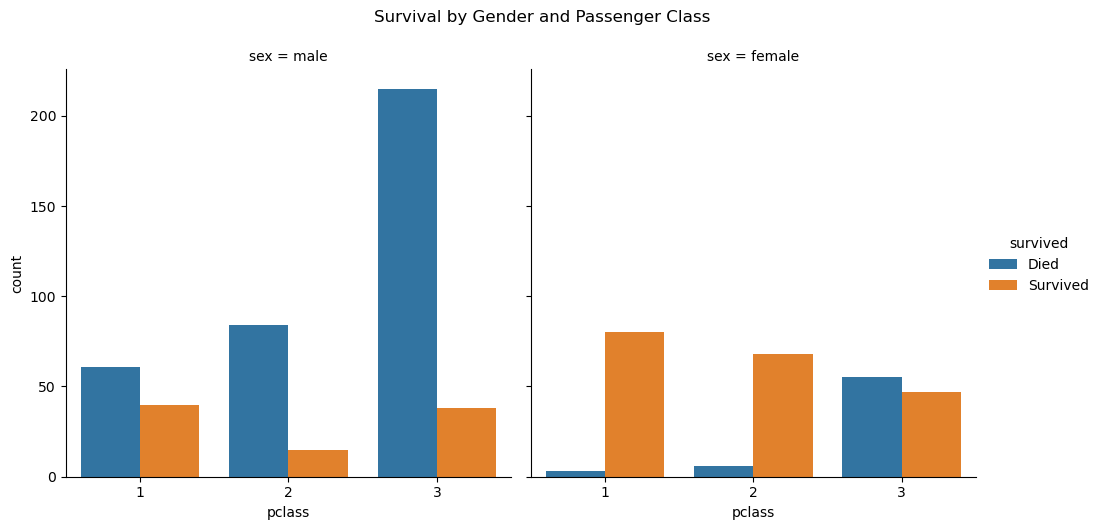

In [29]:
# 시각화2
# 성별 + 선실 등급별 생존자 수 시각화
sns.catplot(
    data=titanic,
    x='pclass',
    hue='survived',
    col='sex',
    kind='count',
    height=5,
    aspect=1
)
plt.suptitle('Survival by Gender and Passenger Class', y=1.05)
plt.show()


In [ ]:
# 분석: 여성 승객의 생존률이 매우 높으며 특히 1등실 여성은 거의 대부분 생존.
# 남성 승객은 전반적으로 낮은 생존률을 보이고, 선실 등급이 낮을수록 생존률 크게 하락.

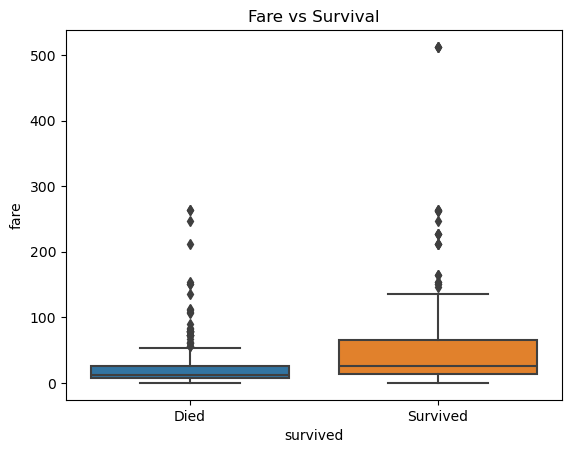

In [30]:
#시각화 3
# 운임(fare)과 생존자 관계 박스플롯

sns.boxplot(data=titanic, x='survived', y='fare')
plt.title('Fare vs Survival')
plt.show()

In [ ]:
# 분석: 생존한 승객들의 운임이 비생존자보다 상대적으로 높게 분포.
# 높은 운임을 지불한 승객이 더 높은 생존률을 가짐을 알 수 있음.

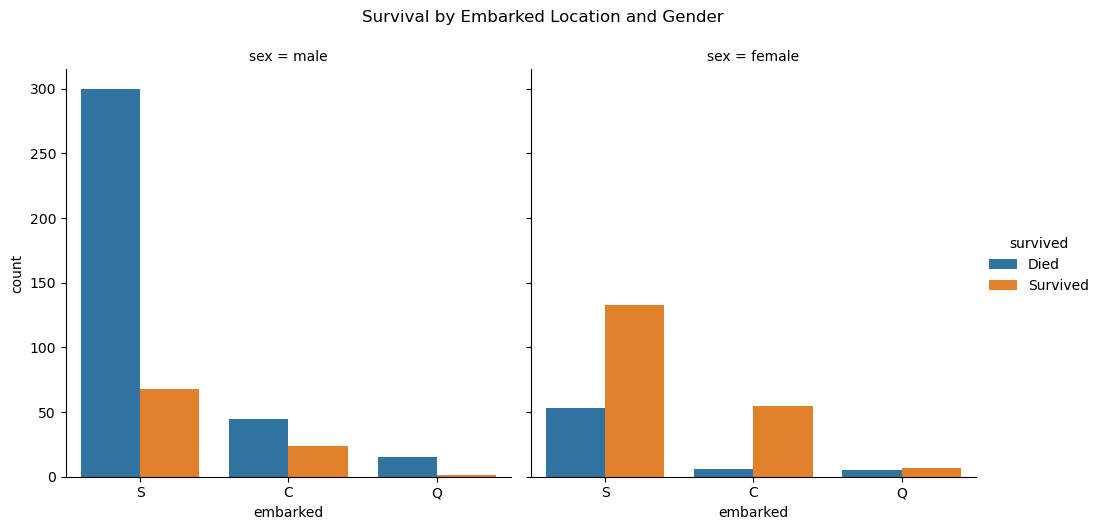

In [31]:
# --- 시각화 4 ---
# 탑승 장소(embarked) + 성별(sex) + 생존률 관계 분석
titanic2 = titanic.dropna(subset=['embarked'])

sns.catplot(
    data=titanic2,
    x='embarked',
    hue='survived',
    col='sex',
    kind='count',
    height=5,
    aspect=1
)
plt.suptitle('Survival by Embarked Location and Gender', y=1.05)
plt.show()

In [ ]:
# 분석: 성별에 따라 탑승 장소별 생존률 차이가 있으며,
# 특히 여성 승객은 모든 탑승지에서 비교적 높은 생존률을 보임.

In [ ]:
# 운임(fare) 구간별 생존률 분포 박스플롯

C:\Users\user\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
C:\Users\user\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
C:\Users\user\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gr

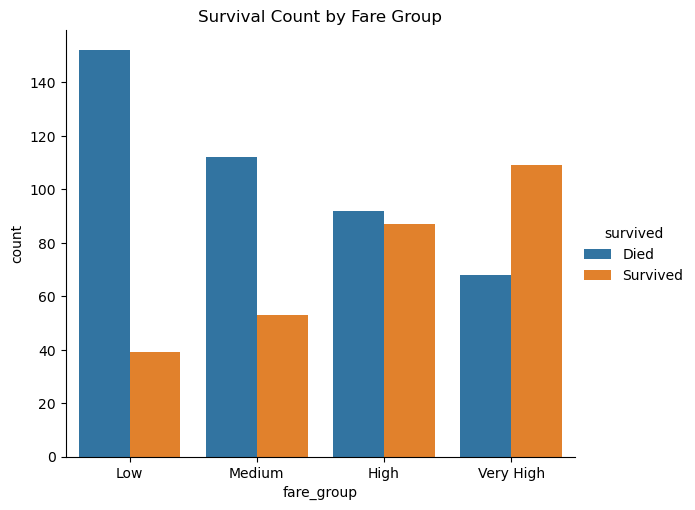

In [33]:
# 운임을 구간화
titanic['fare_group'] = pd.qcut(titanic['fare'], q=4, labels=['Low', 'Medium', 'High', 'Very High'])

# 운임 그룹별 생존자 비율 시각화
sns.catplot(
    data=titanic,
    x='fare_group',
    hue='survived',
    kind='count',
    height=5,
    aspect=1.2
)
plt.title('Survival Count by Fare Group')
plt.show()


In [34]:
# 선실 등급(pclass) + 나이 그룹별 생존률 비교

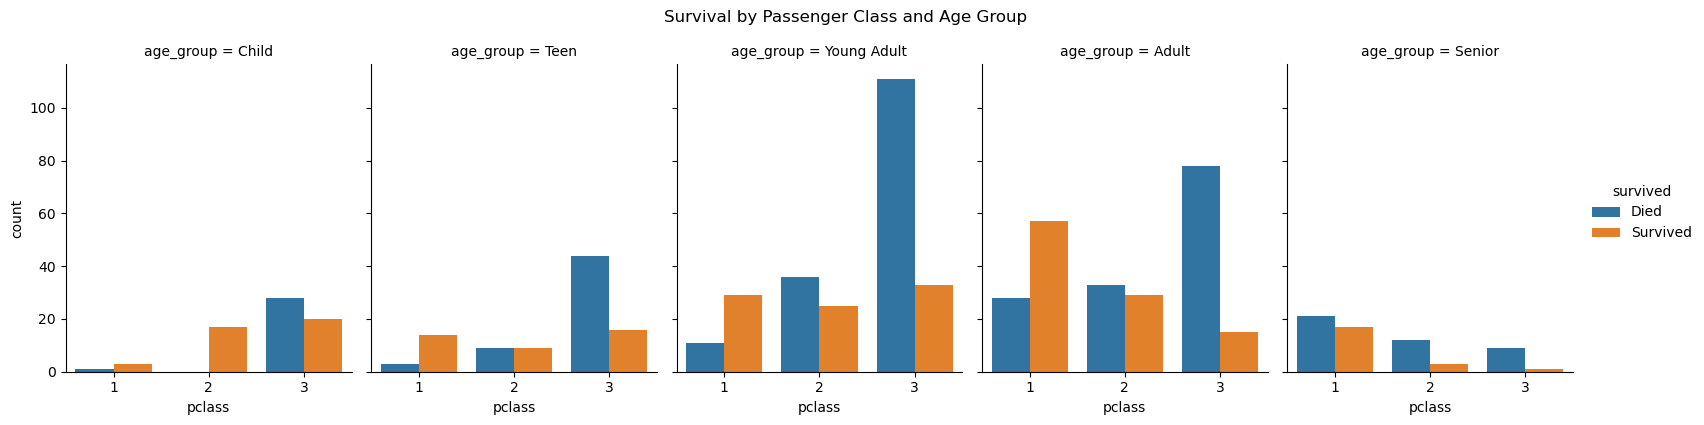

In [35]:
sns.catplot(
    data=titanic,
    x='pclass',
    hue='survived',
    col='age_group',
    kind='count',
    height=4,
    aspect=0.8
)
plt.suptitle('Survival by Passenger Class and Age Group', y=1.05)
plt.show()


In [36]:
# 가족 동반 여부에 따른 성별 생존률 비교

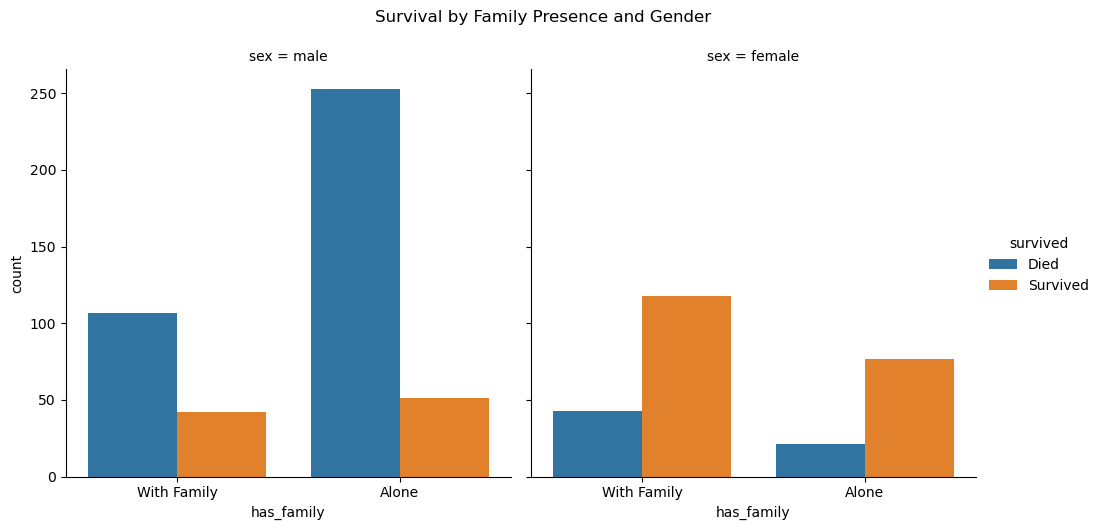

In [37]:
sns.catplot(
    data=titanic,
    x='has_family',
    hue='survived',
    col='sex',
    kind='count',
    height=5,
    aspect=1
)
plt.suptitle('Survival by Family Presence and Gender', y=1.05)
plt.show()
